In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.warp import reproject
from affine import Affine
from matplotlib import pyplot as plt
import cartopy.feature as cf 
import cartopy.crs as ccrs
from shapely.geometry import box
from tqdm import tqdm
from pathlib import Path
import os
import math

In [2]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"

In [ ]:
country_raster_1km_  = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-1km.tif')
country_raster_10km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-10km.tif')
country_raster_50km_ = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-50km.tif')

In [ ]:
# DATA = Path('F:/aggregates-mining-biodiversity/data')

In [19]:
PA_DIR = DATA / 'protected-area'

polygons_0 = gpd.read_file(PA_DIR / 'WDPA_Jul2024_Public_shp_0' / 'WDPA_Jul2024_Public_shp-polygons.shp')
polygons_1 = gpd.read_file(PA_DIR / 'WDPA_Jul2024_Public_shp_1' / 'WDPA_Jul2024_Public_shp-polygons.shp')
polygons_2 = gpd.read_file(PA_DIR / 'WDPA_Jul2024_Public_shp_2' / 'WDPA_Jul2024_Public_shp-polygons.shp')

In [20]:
points_0 = gpd.read_file(PA_DIR / 'WDPA_Jul2024_Public_shp_0' / 'WDPA_Jul2024_Public_shp-points.shp')
points_1 = gpd.read_file(PA_DIR / 'WDPA_Jul2024_Public_shp_1' / 'WDPA_Jul2024_Public_shp-points.shp')
points_2 = gpd.read_file(PA_DIR / 'WDPA_Jul2024_Public_shp_2' / 'WDPA_Jul2024_Public_shp-points.shp')

In [21]:
polygons_all = gpd.GeoDataFrame(pd.concat([polygons_0, polygons_1, polygons_2], ignore_index=True), crs=polygons_0.crs)
points_all = gpd.GeoDataFrame(pd.concat([points_0, points_1, points_2], ignore_index=True), crs=points_0.crs)

In [22]:
len(polygons_all)

283894

In [23]:
polygons_0.columns

Index(['WDPAID', 'WDPA_PID', 'PA_DEF', 'NAME', 'ORIG_NAME', 'DESIG',
       'DESIG_ENG', 'DESIG_TYPE', 'IUCN_CAT', 'INT_CRIT', 'MARINE',
       'REP_M_AREA', 'GIS_M_AREA', 'REP_AREA', 'GIS_AREA', 'NO_TAKE',
       'NO_TK_AREA', 'STATUS', 'STATUS_YR', 'GOV_TYPE', 'OWN_TYPE',
       'MANG_AUTH', 'MANG_PLAN', 'VERIF', 'METADATAID', 'SUB_LOC',
       'PARENT_ISO', 'ISO3', 'SUPP_INFO', 'CONS_OBJ', 'geometry'],
      dtype='object')

In [24]:
polygons_all['pseudo_code'] = np.nan
polygons_all.loc[polygons_all['IUCN_CAT'] == 'Ia', 'pseudo_code'] = 8
polygons_all.loc[polygons_all['IUCN_CAT'] == 'Ib', 'pseudo_code'] = 7
polygons_all.loc[polygons_all['IUCN_CAT'] == 'II', 'pseudo_code'] = 6
polygons_all.loc[polygons_all['IUCN_CAT'] == 'III', 'pseudo_code'] = 5
polygons_all.loc[polygons_all['IUCN_CAT'] == 'IV', 'pseudo_code'] = 4
polygons_all.loc[polygons_all['IUCN_CAT'] == 'V', 'pseudo_code'] = 3
polygons_all.loc[polygons_all['IUCN_CAT'] == 'VI', 'pseudo_code'] = 2
polygons_all.loc[polygons_all['IUCN_CAT'].isin(['Not Applicable', 'Not Reported', 'Not Assigned']), 'pseudo_code'] = 1

In [25]:
polygons_all_eck4 = polygons_all.to_crs("ESRI:54012")

In [27]:
PA_shapes = [(a_shape, a_value) for a_shape, a_value in zip(polygons_all_eck4.geometry, polygons_all_eck4['pseudo_code'])]

In [28]:
PA_raster_1km = rasterize(
    shapes=PA_shapes, 
    out_shape=country_raster_1km_.shape, 
    fill=0, 
    transform=country_raster_1km_.transform,
    dtype=np.uint8)

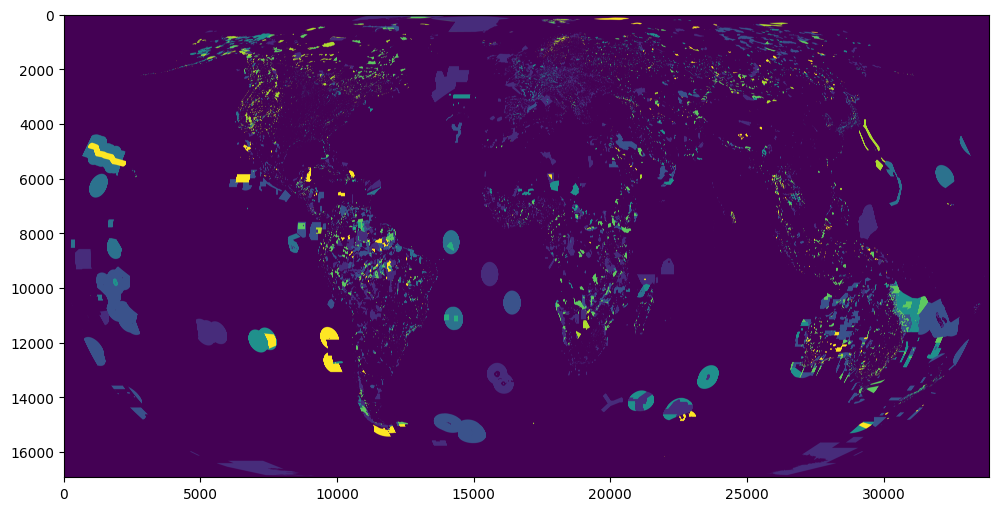

In [36]:
fig = plt.figure(figsize=(10, 5), constrained_layout=True)
plt.imshow(PA_raster_1km)
plt.show()

In [ ]:
PA_RASTER_DIR = RESULTS / 'protected-area-rasters'
PA_RASTER_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
with rio.open(
    PA_RASTER_DIR / 'protected-area-raster.tif',
    'w',
    driver='GTiff',
    height=PA_raster_1km.shape[0],
    width=PA_raster_1km.shape[1],
    count=1,
    dtype=PA_raster_1km.dtype, 
    crs='ESRI:54012',
    transform=country_raster_1km_.transform,
    compress='lzw',
) as dst:
    dst.write(PA_raster_1km, 1)

## protected area masks

In [20]:
mask_names = dict({
    8: 'protected-area-Ia',
    7: 'protected-area-Ib',
    6: 'protected-area-II',
    5: 'protected-area-III',
    4: 'protected-area-IV',
    3: 'protected-area-V',
    2: 'protected-area-VI',
})

In [ ]:
for i in range(2, 9):
    print(mask_names[i])
    a_PA_mask = np.where(PA_raster_1km == i, 1, 0)
    with rio.open(
        PA_RASTER_DIR / f'{mask_names[i]}-mask.tif',
        'w',
        driver='GTiff',
        height=PA_raster_1km.shape[0],
        width=PA_raster_1km.shape[1],
        count=1,
        dtype=PA_raster_1km.dtype, 
        crs='ESRI:54012',
        transform=country_raster_1km_.transform,
        compress='lzw',
    ) as dst:
        dst.write(a_PA_mask, 1)

protected-area-VI
protected-area-V
protected-area-IV
protected-area-III
protected-area-II
protected-area-Ib
protected-area-Ia


In [26]:
unprotected_mask = np.where(PA_raster_1km == 0, 1, 0)

In [ ]:
with rio.open(
    PA_RASTER_DIR / 'unprotected-mask.tif',
    'w',
    driver='GTiff',
    height=PA_raster_1km.shape[0],
    width=PA_raster_1km.shape[1],
    count=1,
    dtype=PA_raster_1km.dtype, 
    crs='ESRI:54012',
    transform=country_raster_1km_.transform,
    compress='lzw',
) as dst:
    dst.write(unprotected_mask, 1)

reproject 1-km PA mask to 50-km resolution

In [ ]:
for aa in tqdm(['Ia', 'Ib', 'II', 'III', 'IV', 'V', 'VI']):
# for aa in tqdm(['Ia']):
    input_path = PA_RASTER_DIR / f'protected-area-{aa}-mask.tif'
    PA_mask_1km  = rio.open(input_path).read(1)
    PA_mask_50km = np.zeros(country_raster_50km_.shape, dtype=np.uint16)
    reproject(
        source=PA_mask_1km,
        destination=PA_mask_50km,
        src_transform=country_raster_1km_.transform,
        src_crs=country_raster_1km_.crs,
        dst_transform=country_raster_50km_.transform,
        dst_crs=country_raster_50km_.crs,
        resampling=Resampling.sum,
    )

    output_path = PA_RASTER_DIR / f'protected-area-{aa}-50km.tif'
    with rio.open(
        output_path,
        'w',
        driver='GTiff',
        height=PA_mask_50km.shape[0],
        width=PA_mask_50km.shape[1],
        count=1,
        dtype=PA_mask_50km.dtype,
        crs=country_raster_50km_.crs,
        transform=country_raster_50km_.transform,
        compress='lzw',
    ) as dst:
        dst.write(PA_mask_50km, 1)